# Strategy research walkthrough

This notebook walks through the full evaluation of the three strategies in
this repository on the Dow Jones, using the same `backtester` package as the
command-line scripts. Every number here can be reproduced with the scripts;
the notebook just puts the reasoning next to the results.

**Question:** does any of these simple rules deliver better risk-adjusted
returns than holding the index, out of sample?

In [1]:
import sys
from pathlib import Path

sys.path.insert(0, str(Path.cwd().parent))  # run from notebooks/

import matplotlib.pyplot as plt
import pandas as pd

from backtester.analysis import bootstrap_sharpe, cost_sweep
from backtester.data import load_prices
from backtester.engine import split_backtest, walk_forward
from backtester.metrics import format_metrics, metrics, relative_metrics, trade_stats
from backtester.plotting import drawdown
from backtester.strategies import breakout_signals, mean_reversion_signals, momentum_signals

pd.set_option("display.precision", 3)
plt.rcParams["figure.dpi"] = 80

## 1. Data

Eight years of daily closes. The loader caches downloads for the day and
warns loudly if it has to fall back to synthetic data, so check the line
below says *real* bars.

Loaded 2010 cached bars for ^DJI from /Users/ehsanghoreishi/quant-backtester/.cache/_DJI_8y_20261021.csv


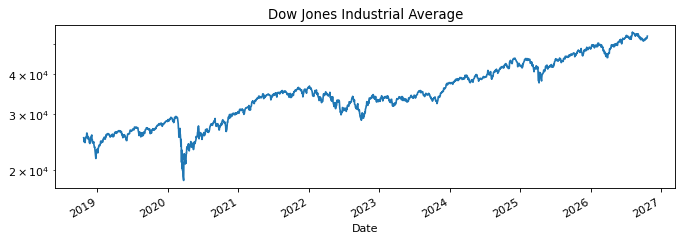

In [2]:
prices = load_prices("^DJI", years=8)
assert prices.attrs["source"] != "synthetic", "results below would not be real"
prices.plot(title="Dow Jones Industrial Average", figsize=(10, 3), logy=True);

## 2. Signals and the out-of-sample split

Each strategy produces positions on the **full** history (indicators only
look backwards and positions are delayed by one bar, so this is leak-free),
which are then split 70/30 in time. Only the last 30% is used to judge.

In [3]:
strategies = {
    "Mean-Reversion": mean_reversion_signals(prices, lookback=20, entry_z=1.0),
    "Momentum": momentum_signals(prices, fast=50, slow=200),
    "Breakout": breakout_signals(prices, entry=55, exit=20),
}
tests = {name: split_backtest(prices, pos)[1] for name, pos in strategies.items()}

table = {name: metrics(bt["strat_ret"]) for name, bt in tests.items()}
table["Buy & Hold"] = metrics(next(iter(tests.values()))["market_ret"])
pd.DataFrame({k: format_metrics(v) for k, v in table.items()})

,Mean-Reversion,Momentum,Breakout,Buy & Hold
Total Return,-13.4%,20.7%,0.1%,35.9%
Annualized Return,-5.8%,8.2%,0.0%,13.7%
Annualized Vol,13.2%,13.7%,8.5%,14.5%
Sharpe,-0.39,0.64,0.05,0.96
Sortino,-0.57,0.95,0.07,1.43
Calmar,-0.28,0.50,0.00,0.83
Max Drawdown,-20.5%,-16.4%,-9.5%,-16.4%


None of the three beats buy & hold on Sharpe. Momentum comes closest.
The trade statistics and the regression on the index explain *how* each
strategy differs from the market:

In [4]:
rows = {}
for name, bt in tests.items():
    rows[name] = {**trade_stats(bt), **relative_metrics(bt["strat_ret"], bt["market_ret"])}
pd.DataFrame(rows).T

,Trades,Trades per Year,Win Rate,Avg Trade,Time in Market,Beta,Alpha (ann.),Correlation,Tracking Error,Information Ratio
Mean-Reversion,33.0,13.791,0.485,-3.941e-03,0.857,0.156,-0.073,0.172,0.178,-1.066
Momentum,2.0,0.836,1.000,1.030e-01,0.902,0.897,-0.036,0.947,0.047,-1.080
Breakout,9.0,3.761,0.444,4.949e-04,0.564,0.344,-0.044,0.586,0.117,-1.146


Momentum is 95% correlated with the index with a beta of 0.9: for most of
the test period it simply *is* the index, minus the time it spends out of
the market. Mean-reversion is nearly uncorrelated, but with negative alpha:
different, not better.

## 3. Equity and drawdown

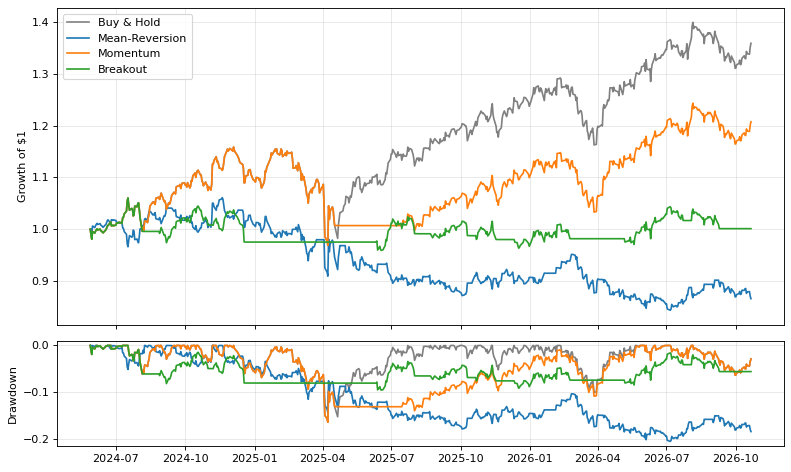

In [5]:
fig, (ax, ax_dd) = plt.subplots(2, 1, figsize=(10, 6), sharex=True,
                               gridspec_kw={"height_ratios": [3, 1]})
market = next(iter(tests.values()))["market_equity"]
ax.plot(market, color="grey", label="Buy & Hold")
ax_dd.plot(drawdown(market), color="grey")
for name, bt in tests.items():
    ax.plot(bt["strat_equity"], label=name)
    ax_dd.plot(drawdown(bt["strat_equity"]))
ax.set_ylabel("Growth of $1")
ax.legend()
ax.grid(alpha=0.3)
ax_dd.set_ylabel("Drawdown")
ax_dd.grid(alpha=0.3)
fig.tight_layout()

## 4. Is any of this more than luck?

About 600 test days is not much. A block bootstrap (20-day blocks) gives a
95% interval for each Sharpe ratio and for its difference to buy & hold.

In [6]:
boot = {}
for name, bt in tests.items():
    own = bootstrap_sharpe(bt["strat_ret"])
    diff = bootstrap_sharpe(bt["strat_ret"], bench=bt["market_ret"])
    boot[name] = {"Sharpe low": own["low"], "Sharpe high": own["high"],
                  "Diff low": diff["low"], "Diff high": diff["high"],
                  "P(<= buy & hold)": diff["p_le_zero"]}
pd.DataFrame(boot).T

,Sharpe low,Sharpe high,Diff low,Diff high,P(<= buy & hold)
Mean-Reversion,-1.257,0.414,-2.968,-0.120,0.986
Momentum,-0.393,1.845,-0.791,0.021,0.964
Breakout,-1.040,1.195,-2.068,0.233,0.939


Every Sharpe interval for the strategies includes zero, so not even
momentum's positive result is statistically distinguishable from no edge.
Mean-reversion's whole difference interval is below zero: it is reliably
worse than holding the index.

## 5. Robustness: other periods and other cost assumptions

A single split can be lucky. Five consecutive out-of-sample periods:

In [7]:
wf = {}
for name, pos in strategies.items():
    folds = walk_forward(prices, pos, n_folds=5)
    wf[name] = {f"{bt.index[0]:%Y-%m}": metrics(bt["strat_ret"])["Sharpe"] for bt in folds}
wf["Buy & Hold"] = {f"{bt.index[0]:%Y-%m}": metrics(bt["market_ret"])["Sharpe"] for bt in folds}
pd.DataFrame(wf)

,Mean-Reversion,Momentum,Breakout,Buy & Hold
2020-02,-0.193,-0.449,0.449,0.609
2021-06,0.007,-0.249,-1.161,-0.372
2022-10,-0.732,0.815,1.410,1.489
2024-02,-0.323,0.141,-0.524,0.543
2025-06,-0.476,1.209,0.224,1.326


In [8]:
pd.concat({name: cost_sweep(prices, pos)["Sharpe"] for name, pos in strategies.items()}, axis=1)

,Mean-Reversion,Momentum,Breakout
cost (bps),,,
0,-0.349,0.644,0.066
2,-0.390,0.642,0.048
5,-0.452,0.639,0.021
10,-0.554,0.635,-0.023
20,-0.756,0.626,-0.111


Only one period, the 2021-22 decline, sees a strategy beat buy & hold, and
there it is mean-reversion and momentum that win simply by losing less.

Costs matter for the strategies that trade: breakout goes from slightly
positive to negative between 5 and 10 bps, and mean-reversion degrades
steadily. But mean-reversion is negative even at zero cost, so costs are not
the reason it fails. Momentum barely trades and is unaffected.

## Conclusion

* None of the three strategies beats buy & hold on the Dow out of sample:
  not on the 70/30 split, not consistently across five sub-periods, and
  not with statistical confidence.
* Momentum is the best of the three: positive on every asset tested
  (`compare_assets.py`) and robust to costs and parameters
  (`sensitivity.py`), but it behaves like a de-risked index position rather
  than a source of alpha.
* Mean-reversion on a trending index is reliably worse than doing nothing.

Negative results like these are the honest outcome for simple rules on a
liquid index, and showing them clearly is the purpose of the project.